# 04 · ทดสอบ `processing_lock.py` กับ OASIS-1 จริง (ฝั่ง 3D = ต้นแบบให้ 2D / 2.5D)

In [1]:
# ======= ตั้งค่า (แก้แค่เซลล์นี้) =======
import os, sys, json, time, glob, hashlib, collections, random
import numpy as np
import matplotlib.pyplot as plt

SHARED_DIR = "."                      # โฟลเดอร์ที่วาง split.json / processing_lock.py / augmentation_lock.py
SPLIT_PATH = os.path.join(SHARED_DIR, "split.json")
DATA_ROOT  = os.environ.get("OASIS_ROOT", "/home/jovyan/shared/donut/Alzheimer/OAS1")
CACHE_DIR  = "./locked_cache"         # เก็บ cache ที่ล็อก (ทุกโมเดลต้องใช้ไฟล์ชุดเดียวกัน)

EXPECT_SIZES = (163, 35, 36)          # train / val / test
EXPECT_CROP  = (137, 171, 145)        # ขนาดหลังตัดพื้นดำ (จาก 00_Review_Data)
ROTATE_DEG   = 15
MODE         = "3D"                   # <<< เพื่อนเปลี่ยนเป็น "2D" หรือ "2.5D" ในเทมเพลตข้อ 6
SEED         = 1334

sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL
print(PL.describe())
print("DATA_ROOT =", DATA_ROOT)

processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)
DATA_ROOT = /home/jovyan/shared/donut/Alzheimer/OAS1


In [2]:
# ตัวช่วยบันทึกผลตรวจ
RESULTS = []
def check(name, ok, detail=""):
    ok = bool(ok)
    RESULTS.append({"name": name, "ok": ok, "detail": str(detail)})
    print(("✅" if ok else "❌"), name, ("| " + str(detail)) if detail != "" else "")

def warn(name, detail=""):
    RESULTS.append({"name": name, "ok": None, "detail": str(detail)})
    print("⚠️ ", name, ("| " + str(detail)) if detail != "" else "")

## 1) ตรวจ `split.json`

In [3]:
with open(SPLIT_PATH) as f:
    split = json.load(f)
labels = split["labels"]
train_ids, val_ids, test_ids = split["train"], split["val"], split["test"]
ALL_IDS = sorted(labels.keys())

check("ขนาด train/val/test ตรงที่ล็อก", (len(train_ids), len(val_ids), len(test_ids)) == EXPECT_SIZES,
      f"{len(train_ids)}/{len(val_ids)}/{len(test_ids)}")
check("ไม่มีคนซ้ำข้าม split", len(set(train_ids) | set(val_ids) | set(test_ids)) == len(train_ids) + len(val_ids) + len(test_ids))
check("ไม่มีคนซ้ำในแต่ละ split", all(len(set(s)) == len(s) for s in (train_ids, val_ids, test_ids)))
check("รวม 3 split = labels ทั้งหมด", set(train_ids) | set(val_ids) | set(test_ids) == set(ALL_IDS), len(ALL_IDS))
check("id เป็นสตริง 4 หลัก", all(isinstance(s, str) and len(s) == 4 and s.isdigit() for s in ALL_IDS))
check("label มีแค่ 0 กับ 1", set(labels.values()) <= {0, 1})
for name, ids in (("train", train_ids), ("val", val_ids), ("test", test_ids)):
    n1 = sum(labels[s] for s in ids)
    print(f"  {name}: Normal {len(ids) - n1} | AD {n1}")
SPLIT_HASH = hashlib.sha256(json.dumps({k: split[k] for k in ("train", "val", "test")}, sort_keys=True).encode()).hexdigest()[:10]
print("split_hash =", SPLIT_HASH, " <- ต้องตรงกันทุกโมเดล")

✅ ขนาด train/val/test ตรงที่ล็อก | 163/35/36
✅ ไม่มีคนซ้ำข้าม split 
✅ ไม่มีคนซ้ำในแต่ละ split 
✅ รวม 3 split = labels ทั้งหมด | 234
✅ id เป็นสตริง 4 หลัก 
✅ label มีแค่ 0 กับ 1 
  train: Normal 93 | AD 70
  val: Normal 20 | AD 15
  test: Normal 21 | AD 15
split_hash = b2a7d0b65d  <- ต้องตรงกันทุกโมเดล


## 2) ตรวจภาพดิบทั้ง 234 คน: หลังตัดพื้นดำต้องได้ 137 × 171 × 145

In [4]:
import nibabel as nib

def crop_size(data):
    mask = data > 0
    size = []
    for ax in range(3):
        other = tuple(a for a in range(3) if a != ax)
        idx = np.where(mask.any(axis=other))[0]
        size.append(int(idx.max() - idx.min() + 1))
    return tuple(size)

raw_shapes, crop_shapes, problems, odd = collections.Counter(), collections.Counter(), [], []
t0 = time.time()
for k, sid in enumerate(ALL_IDS):
    try:
        data = np.asarray(nib.load(PL.subject_path(sid, DATA_ROOT)).dataobj)
        raw_shapes[tuple(data.shape)] += 1
        if data.ndim == 4:
            data = data[:, :, :, 0]
        cs = crop_size(data)
        crop_shapes[cs] += 1
        if cs != EXPECT_CROP:
            odd.append((sid, cs))
    except Exception as e:
        problems.append((sid, repr(e)[:120]))
    if (k + 1) % 50 == 0:
        print(f"  ตรวจแล้ว {k + 1}/{len(ALL_IDS)}  ({time.time() - t0:.0f}s)")

print("ขนาดภาพดิบ  :", dict(raw_shapes))
print("ขนาดหลังตัด :", dict(crop_shapes))
if odd:
    print("คนที่ขนาดหลังตัดไม่ใช่ 137x171x145:", odd[:10])
check("เปิดไฟล์ภาพได้ครบทุกคน", len(problems) == 0, problems[:3])
check("ขนาดหลังตัดพื้นดำ = 137x171x145 ทุกคน", dict(crop_shapes) == {EXPECT_CROP: len(ALL_IDS)},
      f"พบ {len(crop_shapes)} แบบ")

  ตรวจแล้ว 50/234  (0s)
  ตรวจแล้ว 100/234  (0s)
  ตรวจแล้ว 150/234  (1s)
  ตรวจแล้ว 200/234  (1s)
ขนาดภาพดิบ  : {(176, 208, 176, 1): 234}
ขนาดหลังตัด : {(137, 171, 145): 234}
✅ เปิดไฟล์ภาพได้ครบทุกคน | []
✅ ขนาดหลังตัดพื้นดำ = 137x171x145 ทุกคน | พบ 1 แบบ


## 3) สร้าง / โหลด cache ที่ล็อก แล้วตรวจค่า

In [5]:
cache_file = os.path.join(CACHE_DIR, PL.CACHE_NAME)
if os.path.exists(cache_file):
    print("พบ cache เดิม ใช้ไฟล์เดิม:", cache_file)
else:
    t0 = time.time()
    PL.build_cache(ALL_IDS, CACHE_DIR, DATA_ROOT)
    print(f"สร้าง cache เสร็จ ({time.time() - t0:.0f}s)")

with open(os.path.join(CACHE_DIR, PL.META_NAME)) as f:
    meta = json.load(f)
arr = PL.load_locked(ALL_IDS, CACHE_DIR, check=True)       # (N,128,128,96)

check("shape = (N,128,128,96)", arr.shape == (len(ALL_IDS),) + PL.TARGET_SHAPE, arr.shape)
check("dtype float32", arr.dtype == np.float32, arr.dtype)
check("ไม่มี NaN / Inf", np.isfinite(arr).all())
check("ค่าอยู่ใน [0,1]", arr.min() >= 0 and arr.max() <= 1, f"min {arr.min():.3f} max {arr.max():.3f}")
check("ทุกคนมี max สูง (~1) และไม่ใช่ภาพว่าง", (arr.reshape(len(arr), -1).max(1) > 0.9).all())
check("preprocess_hash ใน meta = ค่าที่ล็อก", meta["preprocess_hash"] == PL.preprocess_hash(), PL.preprocess_hash())
sums = [PL.volume_checksum(v) for v in arr]
check("checksum รายคนไม่ซ้ำกัน (ไม่ได้โหลดไฟล์เดียวซ้ำ)", len(set(sums)) == len(sums))

พบ cache เดิม ใช้ไฟล์เดิม: ./locked_cache/locked_volumes_128x128x96.npy
[processing_lock] โหลด 234 volume | shape (128, 128, 96) | hash 22275bfd6b
✅ shape = (N,128,128,96) | (234, 128, 128, 96)
✅ dtype float32 | float32
✅ ไม่มี NaN / Inf 
✅ ค่าอยู่ใน [0,1] | min 0.000 max 1.000
✅ ทุกคนมี max สูง (~1) และไม่ใช่ภาพว่าง 
✅ preprocess_hash ใน meta = ค่าที่ล็อก | 22275bfd6b
✅ checksum รายคนไม่ซ้ำกัน (ไม่ได้โหลดไฟล์เดียวซ้ำ) 


In [6]:
# ความนิ่ง: ประมวลผลใหม่จากไฟล์ดิบ 5 คน ต้องได้ภาพ/checksum เดิม
rng = random.Random(0)
pick = rng.sample(ALL_IDS, 5)
same_sum, same_arr = [], []
for sid in pick:
    v2 = PL.load_volume(sid, DATA_ROOT)
    same_sum.append(PL.volume_checksum(v2) == meta["checksums"][sid])
    same_arr.append(np.array_equal(v2, arr[ALL_IDS.index(sid)]))
check("ประมวลผลซ้ำจากไฟล์ดิบ checksum ตรงกับ cache", all(same_sum), pick)
check("ประมวลผลซ้ำจากไฟล์ดิบ ค่าตรงกับ cache ทุก voxel", all(same_arr))

FP = PL.locked_fingerprint(arr, ALL_IDS)
FP2 = PL.locked_fingerprint(PL.load_locked(ALL_IDS, CACHE_DIR, verbose=False), ALL_IDS)
check("fingerprint โหลดสองครั้งตรงกัน", FP == FP2, FP)
print("fingerprint =", FP, " <- เทียบกับเพื่อน ต้องเป็นค่าเดียวกัน (ถ้าโหลดรายชื่อ ALL_IDS เหมือนกัน)")

# เก็บภาพแยกตาม split ไว้ใช้ต่อ
idx = {s: i for i, s in enumerate(ALL_IDS)}
vol_of = lambda sid: arr[idx[sid]]

✅ ประมวลผลซ้ำจากไฟล์ดิบ checksum ตรงกับ cache | ['0430', '0203', '0374', '0451', '0217']
✅ ประมวลผลซ้ำจากไฟล์ดิบ ค่าตรงกับ cache ทุก voxel 
✅ fingerprint โหลดสองครั้งตรงกัน | ddcf1dad7a
fingerprint = ddcf1dad7a  <- เทียบกับเพื่อน ต้องเป็นค่าเดียวกัน (ถ้าโหลดรายชื่อ ALL_IDS เหมือนกัน)


## 4) `make_input` และการหมุนบนภาพจริง

In [7]:
from scipy.ndimage import rotate as sp_rotate
cx, cy, cz = PL.CENTER
v0 = vol_of(train_ids[0])

check("3D shape", PL.make_input(v0, "3D").shape == (1, 128, 128, 96), PL.make_input(v0, "3D").shape)
check("2D shape", PL.make_input(v0, "2D").shape == (1, 128, 128))
check("2.5D shape", PL.make_input(v0, "2.5D").shape == (3, 128, 128))
check("2D out_size=224", PL.make_input(v0, "2D", out_size=224).shape == (1, 224, 224))
check("2.5D out_size=224", PL.make_input(v0, "2.5D", out_size=224).shape == (3, 224, 224))
check("ภาพไม่หมุน: 2D = ชิ้น z=48", np.array_equal(PL.make_input(v0, "2D")[0], v0[:, :, cz]))

worst = 0.0
for sid in (train_ids[0], val_ids[0], test_ids[0]):
    v = vol_of(sid)
    for ang in (0.0, 7.3, -15.0, 15.0):
        ref = sp_rotate(v, ang, axes=(0, 1), reshape=False, order=1, mode="nearest") if ang else v
        i3 = PL.make_input(v, "3D", ang)[0]
        i2 = PL.make_input(v, "2D", ang)[0]
        i25 = PL.make_input(v, "2.5D", ang)
        d = [np.abs(i3 - ref).max(), np.abs(i2 - ref[:, :, cz]).max()]
        # sagittal / coronal (128x96) ถูกขยายเป็นสี่เหลี่ยมจัตุรัสใน make_input → เทียบผ่าน planes_of_rotated
        sag, cor, axi = PL.planes_of_rotated(v, ang)
        d += [np.abs(sag - ref[cx, :, :]).max(), np.abs(cor - ref[:, cy, :]).max(), np.abs(axi - ref[:, :, cz]).max()]
        d.append(np.abs(i25[2] - i2).max())            # axial ของ 2.5D = 2D
        worst = max(worst, max(float(x) for x in d))
check("หมุนบนภาพจริง: 3D / 2D / 2.5D ตรงกับ scipy rotate ทั้ง volume", worst < 1e-4, f"ต่างสูงสุด {worst:.2e}")

✅ 3D shape | (1, 128, 128, 96)
✅ 2D shape 
✅ 2.5D shape 
✅ 2D out_size=224 
✅ 2.5D out_size=224 
✅ ภาพไม่หมุน: 2D = ชิ้น z=48 
✅ หมุนบนภาพจริง: 3D / 2D / 2.5D ตรงกับ scipy rotate ทั้ง volume | ต่างสูงสุด 0.00e+00


In [8]:
# มุมจาก augmentation_lock
a1 = AL.angle_for(SEED, 3, 25, ROTATE_DEG)
np.random.seed(0); b1 = AL.angle_for(SEED, 3, 25, ROTATE_DEG)
np.random.seed(99); b2 = AL.angle_for(SEED, 3, 25, ROTATE_DEG)
check("angle_for: ค่าเดิมเมื่อ (seed,epoch,subject) เดิม ไม่ขึ้นกับ RNG ส่วนกลาง", a1 == b1 == b2, a1)
samples = np.array([AL.angle_for(SEED, e, int(s), ROTATE_DEG) for e in range(1, 21) for s in ALL_IDS[:100]])
check("angle_for: อยู่ในช่วง ±15 และกระจายเกือบทั้งช่วง (uniform)",
      samples.min() >= -ROTATE_DEG and samples.max() <= ROTATE_DEG and samples.min() < -14 and samples.max() > 14 and abs(samples.mean()) < 0.5,
      f"min {samples.min():.2f} max {samples.max():.2f} mean {samples.mean():.2f}")
check("angle_for: epoch ต่างกันได้มุมต่างกัน", AL.angle_for(SEED, 1, 25) != AL.angle_for(SEED, 2, 25))

✅ angle_for: ค่าเดิมเมื่อ (seed,epoch,subject) เดิม ไม่ขึ้นกับ RNG ส่วนกลาง | 1.2110128334604866
✅ angle_for: อยู่ในช่วง ±15 และกระจายเกือบทั้งช่วง (uniform) | min -14.96 max 14.98 mean -0.04
✅ angle_for: epoch ต่างกันได้มุมต่างกัน 


## 5) พล็อตเช็คด้วยตา (ควรเห็นสมองอยู่กลางภาพ ระนาบถูกตัดที่ x=64, y=64, z=48)

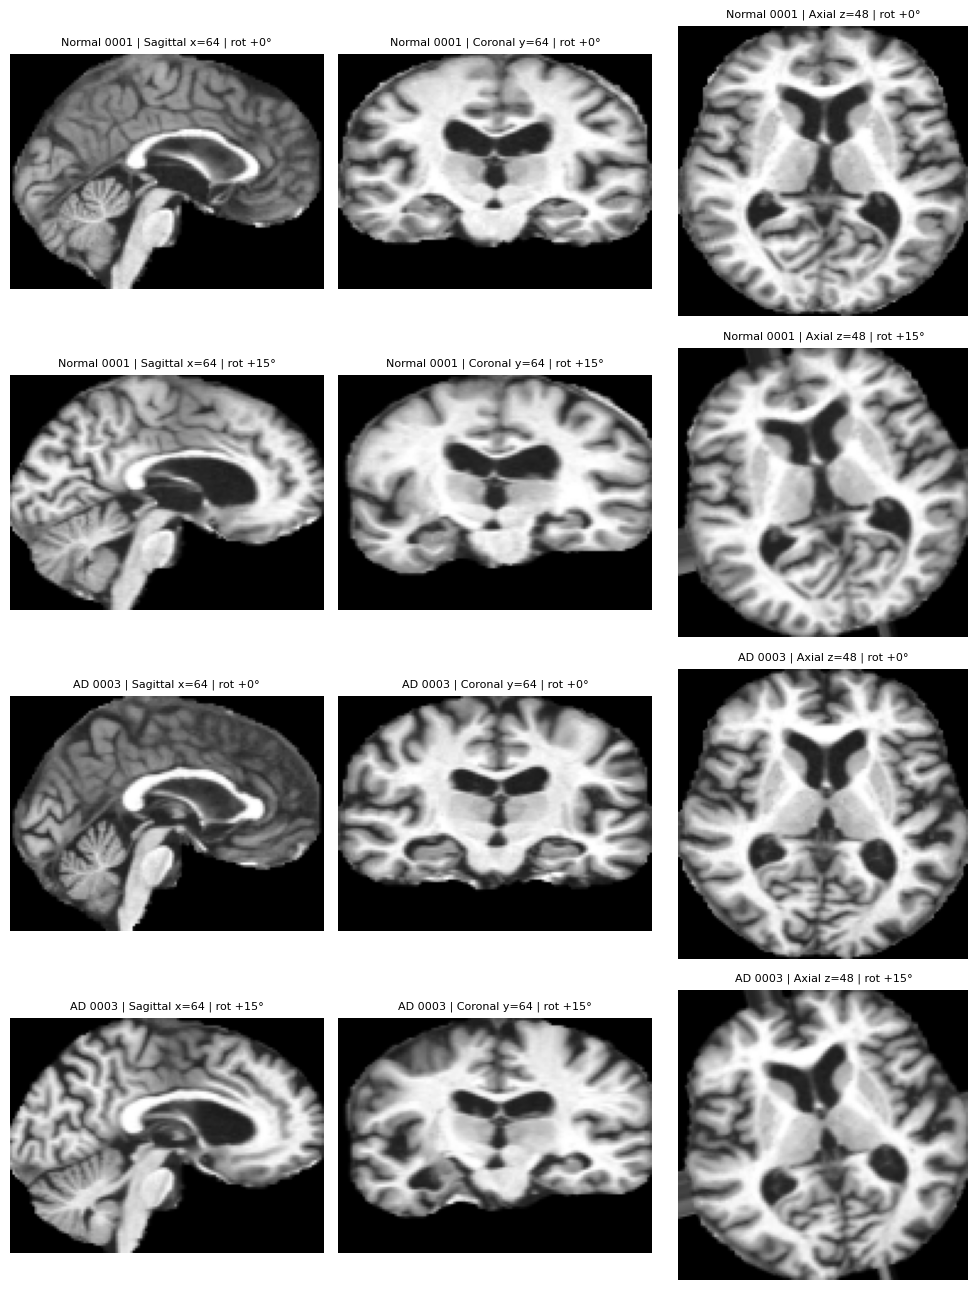

In [9]:
sid_n = next(s for s in train_ids if labels[s] == 0)
sid_a = next(s for s in train_ids if labels[s] == 1)
fig, axes = plt.subplots(4, 3, figsize=(10, 13))
row = 0
for sid in (sid_n, sid_a):
    for ang in (0.0, 15.0):
        sag, cor, axi = PL.planes_of_rotated(vol_of(sid), ang)
        for col, (img, ttl) in enumerate(((sag, f"Sagittal x={cx}"), (cor, f"Coronal y={cy}"), (axi, f"Axial z={cz}"))):
            ax = axes[row, col]
            ax.imshow(img.T, cmap="gray", origin="lower", vmin=0, vmax=1)
            ax.set_title(f"{'Normal' if labels[sid] == 0 else 'AD'} {sid} | {ttl} | rot {ang:+.0f}°", fontsize=8)
            ax.axis("off")
        row += 1
plt.tight_layout()
plt.savefig("fig_processing_lock_check.png", dpi=120)
plt.show()

## 6) เทมเพลตการใช้ไฟล์ล็อกในโน้ตบุ๊กเทรน (ก๊อปไปแปลงเป็น 2D / 2.5D ได้)

In [10]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # ถ้าใช้ GPU ควรตั้งก่อน import torch ในโน้ตบุ๊กเทรนจริง
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

class LockedDataset(Dataset):
    # volumes: (N,128,128,96) จาก PL.load_locked | train=True → หมุนด้วย angle_for, False → ไม่หมุน
    def __init__(self, ids, mode, train, seed, rotate_deg=15, out_size=None):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = np.array([labels[s] for s in self.ids], dtype=np.int64)
        self.mode, self.train, self.seed, self.rotate_deg, self.out_size = mode, train, seed, rotate_deg, out_size
        self.epoch = 1                                   # epoch เริ่มที่ 1 (ต้องตรงกับเพื่อน)
    def set_epoch(self, epoch):
        self.epoch = epoch
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        angle = AL.angle_for(self.seed, self.epoch, int(self.ids[i]), self.rotate_deg) if self.train else 0.0
        x = PL.make_input(self.volumes[i], self.mode, angle, self.out_size)
        return torch.from_numpy(x), int(self.y[i])

def tiny_model(mode):
    # โมเดลเล็กๆ ไว้ทดสอบ pipeline เท่านั้น (ของจริงใช้ ResNet18 / EfficientNet / DenseNet)
    if mode == "3D":
        return nn.Sequential(nn.Conv3d(1, 8, 3, 2, 1), nn.BatchNorm3d(8), nn.ReLU(),
                             nn.Conv3d(8, 16, 3, 2, 1), nn.BatchNorm3d(16), nn.ReLU(),
                             nn.AdaptiveAvgPool3d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(16, 2))
    ch = 1 if mode == "2D" else 3
    return nn.Sequential(nn.Conv2d(ch, 8, 3, 2, 1), nn.BatchNorm2d(8), nn.ReLU(),
                         nn.Conv2d(8, 16, 3, 2, 1), nn.BatchNorm2d(16), nn.ReLU(),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(16, 2))

EXPECT_SHAPE = {"3D": (8, 1, 128, 128, 96), "2D": (8, 1, 128, 128), "2.5D": (8, 3, 128, 128)}[MODE]

In [11]:
set_seed(SEED)
train_ds = LockedDataset(train_ids, MODE, train=True,  seed=SEED, rotate_deg=ROTATE_DEG)
val_ds   = LockedDataset(val_ids,   MODE, train=False, seed=SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, generator=g, num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=8, shuffle=False, num_workers=0)

xb, yb = next(iter(train_dl))
check(f"batch shape ({MODE})", tuple(xb.shape) == EXPECT_SHAPE, tuple(xb.shape))
check("batch dtype float32 / label int64", xb.dtype == torch.float32 and yb.dtype == torch.int64)
check("batch ค่าอยู่ใน [0,1]", float(xb.min()) >= 0 and float(xb.max()) <= 1)

# เทรน: คนเดิม epoch เดียวกัน ต้องได้ภาพเดียวกัน (สองตัว dataset แยกกัน) / epoch ต่างกันต้องต่าง / val ไม่หมุน
ds_a = LockedDataset(train_ids[:6], MODE, True, SEED); ds_b = LockedDataset(train_ids[:6], MODE, True, SEED)
ds_a.set_epoch(3); ds_b.set_epoch(3)
same = all(torch.equal(ds_a[i][0], ds_b[i][0]) for i in range(6))
ds_b.set_epoch(4)
diff = any(not torch.equal(ds_a[i][0], ds_b[i][0]) for i in range(6))
check("augment: seed+epoch+คน เดิม → ภาพเดิมเป๊ะ", same)
check("augment: epoch ต่างกัน → ภาพหมุนต่างกัน", diff)
va = LockedDataset(val_ids[:4], MODE, False, SEED); vb = LockedDataset(val_ids[:4], MODE, False, SEED); vb.set_epoch(9)
check("val ไม่หมุน (epoch ไหนก็เหมือนเดิม)", all(torch.equal(va[i][0], vb[i][0]) for i in range(4)))

✅ batch shape (3D) | (8, 1, 128, 128, 96)
✅ batch dtype float32 / label int64 
✅ batch ค่าอยู่ใน [0,1] 
✅ augment: seed+epoch+คน เดิม → ภาพเดิมเป๊ะ 
✅ augment: epoch ต่างกัน → ภาพหมุนต่างกัน 
✅ val ไม่หมุน (epoch ไหนก็เหมือนเดิม) 


In [12]:
# ความ reproducible ของโมเดล (CPU): seed เดียวกัน → น้ำหนักเริ่มต้นและ output เหมือนเดิม
def init_and_forward():
    set_seed(SEED)
    m = tiny_model(MODE).eval()
    with torch.no_grad():
        return m(xb[:4])
check("seed เดียวกัน → output โมเดลเหมือนเดิม", torch.allclose(init_and_forward(), init_and_forward(), atol=1e-6))

# smoke train สั้นๆ (ไม่ใช่การเทรนจริง แค่ดูว่า pipeline วิ่งได้และ loss ไม่เป็น NaN)
SMOKE_EPOCHS, SMOKE_MAX_BATCHES = 2, 6
device = "cuda" if torch.cuda.is_available() else "cpu"
set_seed(SEED)
model = tiny_model(MODE).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
lossf = nn.CrossEntropyLoss(label_smoothing=0.25)
losses = []
for ep in range(1, SMOKE_EPOCHS + 1):
    train_ds.set_epoch(ep)                               # สำคัญ: บอก dataset ว่าอยู่ epoch ไหน
    model.train()
    for b, (x, y) in enumerate(train_dl):
        if b >= SMOKE_MAX_BATCHES: break
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); loss = lossf(model(x), y); loss.backward(); opt.step()
        losses.append(float(loss))
    print(f"epoch {ep}: loss {np.mean(losses[-SMOKE_MAX_BATCHES:]):.4f}")
model.eval(); correct = n = 0
with torch.no_grad():
    for x, y in val_dl:
        correct += int((model(x.to(device)).argmax(1).cpu() == y).sum()); n += len(y)
check("smoke train: loss เป็นตัวเลขปกติ", np.isfinite(losses).all(), f"first {losses[0]:.3f} last {losses[-1]:.3f}")
print(f"val acc (แค่ดูว่ารันได้ ไม่ใช่ผลจริง): {correct / n:.3f}  device={device}")

✅ seed เดียวกัน → output โมเดลเหมือนเดิม 


/tmp/ipykernel_356/1706856994.py:24: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  losses.append(float(loss))


epoch 1: loss 0.7058
epoch 2: loss 0.6991
✅ smoke train: loss เป็นตัวเลขปกติ | first 0.709 last 0.697
val acc (แค่ดูว่ารันได้ ไม่ใช่ผลจริง): 0.571  device=cuda


## 7) ตรวจ static ว่าโน้ตบุ๊กเทรนจริงเรียกไฟล์ล็อกครบหรือยัง

In [13]:
NOTEBOOKS = [
     "/home/jovyan/Alzheimer's/src/04-model/3D/DenseNet121_k8.ipynb",
     "/home/jovyan/Alzheimer's/src/04-model/3D/EfficientNet_B0_SD0.2.ipynb",
     "/home/jovyan/Alzheimer's/src/04-model/3D/ResNet18_Kernel3.ipynb",
]
MUST = {   # รูปแบบข้อความ (regex) → ความหมาย
    r"split\.json": "อ่านรายชื่อจาก split.json",
    r"processing_lock|load_locked": "ใช้ processing_lock / load_locked",
    r"make_input": "สร้างอินพุตด้วย make_input",
    r"angle_for|augmentation_lock": "ใช้มุมจาก augmentation_lock.angle_for",
    r"manual_seed": "ตั้ง seed (torch.manual_seed)",
    r"cudnn\.deterministic": "cudnn.deterministic",
}
SHOULD_NOT = {
    r"np\.flip|torch\.flip|fliplr|flipud|RandomFlip|RandomHorizontalFlip|RandomVerticalFlip": "พบการ flip (เราตกลงไม่ flip)",
    r"zoom\(|F\.interpolate|transforms\.Resize|Resize\(": "พบการ resize ในโน้ตบุ๊ก (ถ้าเป็นขั้นปรับเข้าโมเดลตามที่ตกลงได้ แต่ห้ามใช้แทน target shape ที่ล็อก)",
    r"train_test_split|StratifiedKFold|StratifiedShuffleSplit": "พบการแบ่งข้อมูลเอง (ต้องใช้ split.json อย่างเดียว ยกเว้นโน้ตบุ๊ก K-Fold)",
    r"random_state\s*=\s*\d+": "พบ random_state (ตรวจว่าไม่ได้ใช้แบ่งข้อมูลเอง)",
}
import re
def code_of(path):
    with open(path, encoding="utf-8") as f:
        nbk = json.load(f)
    return "\n".join("".join(c["source"]) for c in nbk["cells"] if c["cell_type"] == "code")

if not NOTEBOOKS:
    print("ยังไม่ได้ใส่ NOTEBOOKS — ข้ามขั้นนี้ (ใส่ path โน้ตบุ๊กเทรนแล้วรันเซลล์นี้ใหม่)")
for path in NOTEBOOKS:
    if not os.path.exists(path):
        warn(f"ไม่พบโน้ตบุ๊ก {path}"); continue
    src = code_of(path)
    print("\n==", path)
    for pat, msg in MUST.items():
        ok = re.search(pat, src) is not None
        if ok:
            check(f"[{os.path.basename(path)}] {msg}", True)
        else:
            warn(f"[{os.path.basename(path)}] ไม่เจอ: {msg}")
    for pat, msg in SHOULD_NOT.items():
        if re.search(pat, src):
            warn(f"[{os.path.basename(path)}] {msg}")
    m = re.search(r"(?:ROTATE_DEG|ROTATE|rotate_deg|ROTATIONS)\s*=\s*\[?\s*(\d+)", src)
    print("   ค่ามุมหมุนที่พบ:", m.group(1) if m else "ไม่พบ", "(ต้องเป็น 15)")


== /home/jovyan/Alzheimer's/src/04-model/3D/DenseNet121_k8.ipynb
⚠️  [DenseNet121_k8.ipynb] ไม่เจอ: อ่านรายชื่อจาก split.json 
⚠️  [DenseNet121_k8.ipynb] ไม่เจอ: ใช้ processing_lock / load_locked 
⚠️  [DenseNet121_k8.ipynb] ไม่เจอ: สร้างอินพุตด้วย make_input 
⚠️  [DenseNet121_k8.ipynb] ไม่เจอ: ใช้มุมจาก augmentation_lock.angle_for 
✅ [DenseNet121_k8.ipynb] ตั้ง seed (torch.manual_seed) 
✅ [DenseNet121_k8.ipynb] cudnn.deterministic 
⚠️  [DenseNet121_k8.ipynb] พบการ resize ในโน้ตบุ๊ก (ถ้าเป็นขั้นปรับเข้าโมเดลตามที่ตกลงได้ แต่ห้ามใช้แทน target shape ที่ล็อก) 
⚠️  [DenseNet121_k8.ipynb] พบการแบ่งข้อมูลเอง (ต้องใช้ split.json อย่างเดียว ยกเว้นโน้ตบุ๊ก K-Fold) 
⚠️  [DenseNet121_k8.ipynb] พบ random_state (ตรวจว่าไม่ได้ใช้แบ่งข้อมูลเอง) 
   ค่ามุมหมุนที่พบ: 15 (ต้องเป็น 15)

== /home/jovyan/Alzheimer's/src/04-model/3D/EfficientNet_B0_SD0.2.ipynb
⚠️  [EfficientNet_B0_SD0.2.ipynb] ไม่เจอ: อ่านรายชื่อจาก split.json 
⚠️  [EfficientNet_B0_SD0.2.ipynb] ไม่เจอ: ใช้ processing_lock / load_locked 
⚠️ 

## 8) สรุปผล + บันทึกรายงาน

In [14]:
n_ok  = sum(r["ok"] is True  for r in RESULTS)
n_bad = sum(r["ok"] is False for r in RESULTS)
n_warn = sum(r["ok"] is None for r in RESULTS)
print(f"ผ่าน {n_ok} | ไม่ผ่าน {n_bad} | เตือน {n_warn}")
for r in RESULTS:
    if r["ok"] is False:
        print("  ❌", r["name"], "|", r["detail"])

report = {
    "preprocess_hash": PL.preprocess_hash(), "split_hash": SPLIT_HASH, "fingerprint": FP,
    "n_subjects": len(ALL_IDS), "raw_shapes": {str(k): v for k, v in raw_shapes.items()},
    "crop_shapes": {str(k): v for k, v in crop_shapes.items()},
    "versions": {"numpy": np.__version__, "torch": torch.__version__,
                 "scipy": __import__("scipy").__version__, "nibabel": nib.__version__},
    "n_pass": n_ok, "n_fail": n_bad, "n_warn": n_warn, "checks": RESULTS,
}
with open("processing_lock_test_report.json", "w") as f:
    json.dump(report, f, indent=1, ensure_ascii=False)
print("บันทึก processing_lock_test_report.json แล้ว")
assert n_bad == 0, "มีข้อที่ไม่ผ่าน — ดูรายการ ❌ ด้านบน"

ผ่าน 42 | ไม่ผ่าน 0 | เตือน 21
บันทึก processing_lock_test_report.json แล้ว
